# 实验三：图像拼接

本 notebook 把参考代码 image_fusion.py 整理成一条完整流程：读入两张有重叠区域的图像，用 SIFT 提取特征，用 FLANN 做匹配，再用 Lowe 比率检验筛掉错配，最后由 RANSAC 估计单应矩阵，把 b 图透视变换后贴到 a 图上，得到一张拼接图。


## 2.1 导入依赖

OpenCV 负责特征检测、匹配和透视变换，numpy 负责点集和矩阵运算，matplotlib 负责把中间结果画出来。环境没有图形界面，用 Agg 后端，图片直接存文件，同时用 plt.show() 让 Jupyter 里也能看到。


In [1]:
import os
import time

import numpy as np
import cv2
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

BASE = os.getcwd()
OUT_IMG = os.path.join(BASE, 'output_images')
OUT_RES = os.path.join(BASE, 'result')
os.makedirs(OUT_IMG, exist_ok=True)
os.makedirs(OUT_RES, exist_ok=True)


## 2.2 读取图像并转灰度

a.jpg 和 b.jpg 是同一场景左右各拍一张，中间有一部分重叠。特征点检测只需要灰度信息，所以读完先转灰度。


a.jpg 尺寸 (1280, 1068, 3)
b.jpg 尺寸 (1280, 1161, 3)


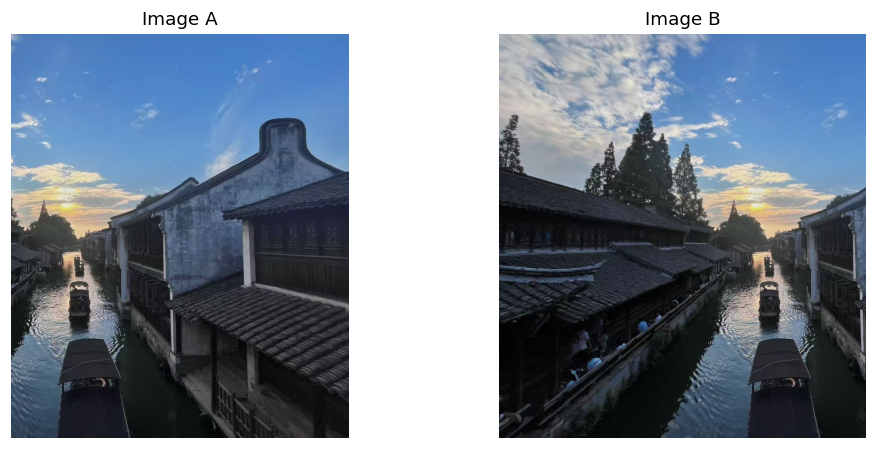

In [2]:
img_a = cv2.imread(os.path.join(BASE, 'a.jpg'))
img_b = cv2.imread(os.path.join(BASE, 'b.jpg'))
assert img_a is not None and img_b is not None, 'a.jpg 或 b.jpg 读取失败'

print('a.jpg 尺寸', img_a.shape)
print('b.jpg 尺寸', img_b.shape)

gray_a = cv2.cvtColor(img_a, cv2.COLOR_BGR2GRAY)
gray_b = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].imshow(cv2.cvtColor(img_a, cv2.COLOR_BGR2RGB))
axes[0].set_title('Image A')
axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(img_b, cv2.COLOR_BGR2RGB))
axes[1].set_title('Image B')
axes[1].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUT_IMG, 'input_images.jpg'), dpi=200, bbox_inches='tight')
plt.show()


## 2.3 SIFT 特征检测

SIFT 先在不同尺度的高斯差分金字塔里找极值点，再给每个关键点算一个 128 维描述符。描述符对尺度、旋转和光照变化都不敏感，所以两张图角度和亮度有差别也能匹配上。


a 图关键点 3192 描述符形状 (3192, 128)
b 图关键点 4411 描述符形状 (4411, 128)


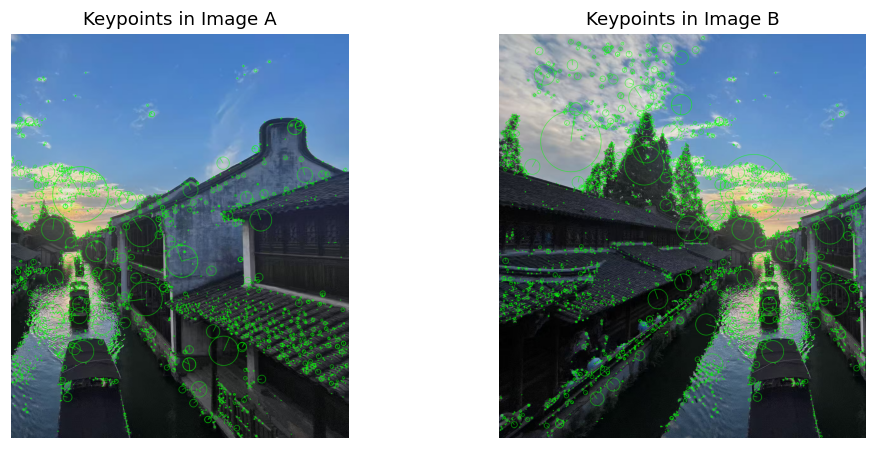

In [3]:
sift = cv2.SIFT_create()
kp_a, des_a = sift.detectAndCompute(gray_a, None)
kp_b, des_b = sift.detectAndCompute(gray_b, None)

print('a 图关键点', len(kp_a), '描述符形状', des_a.shape)
print('b 图关键点', len(kp_b), '描述符形状', des_b.shape)

vis_a = cv2.drawKeypoints(img_a, kp_a, None, color=(0, 255, 0),
                          flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
vis_b = cv2.drawKeypoints(img_b, kp_b, None, color=(0, 255, 0),
                          flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].imshow(cv2.cvtColor(vis_a, cv2.COLOR_BGR2RGB))
axes[0].set_title('Keypoints in Image A')
axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(vis_b, cv2.COLOR_BGR2RGB))
axes[1].set_title('Keypoints in Image B')
axes[1].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUT_IMG, 'keypoints.jpg'), dpi=200, bbox_inches='tight')
plt.show()


## 2.4 FLANN 匹配与 Lowe 比率检验

FLANN 用 KD 树在描述符集合里找近邻，knnMatch 取 k=2，每个点返回最近和次近两个候选。Lowe 比率检验的思路是：只有当最近距离明显小于次近距离（小于 0.7 倍）时才算可靠匹配。如果两个候选差不多近，说明这个点区分度不够，直接丢掉。


knn 返回对数 3192
比率检验后保留 1112


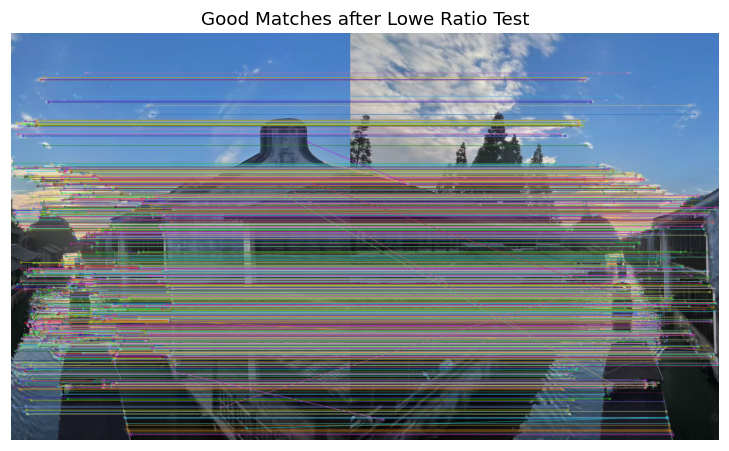

In [4]:
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)
flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des_a, des_b, k=2)

good = []
for m, n in matches:
    if m.distance < 0.7 * n.distance:
        good.append(m)

print('knn 返回对数', len(matches))
print('比率检验后保留', len(good))

match_vis = cv2.drawMatches(img_a, kp_a, img_b, kp_b, good, None,
                            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(12, 4.8))
plt.imshow(cv2.cvtColor(match_vis, cv2.COLOR_BGR2RGB))
plt.title('Good Matches after Lowe Ratio Test')
plt.axis('off')
plt.savefig(os.path.join(OUT_IMG, 'matches.jpg'), dpi=200, bbox_inches='tight')
plt.show()


## 2.5 RANSAC 估计单应矩阵

单应矩阵 H 是一个 3×3 矩阵，把 b 图的像素坐标映射到 a 图的坐标系。匹配点里仍会有少量错配，findHomography 用 RANSAC：每次随机抽 4 对点算一个 H，统计有多少点符合这个 H，重复多次取内点最多的一组，最后用全部内点重算 H。阈值 5.0 是重投影误差的像素容差。


In [5]:
src_pts = np.float32([kp_b[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
dst_pts = np.float32([kp_a[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)

H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
inliers = int(mask.sum()) if mask is not None else 0

print('单应矩阵 H =')
print(np.round(H, 3))
print('内点数', inliers, '内点比例', round(inliers / len(good), 3))

proj = cv2.perspectiveTransform(src_pts, H)
err = np.linalg.norm(proj.reshape(-1, 2) - dst_pts.reshape(-1, 2), axis=1)
print('全部匹配点平均重投影误差', round(float(err.mean()), 2), '像素')
print('内点平均重投影误差', round(float(err[mask.ravel() == 1].mean()), 2), '像素')


单应矩阵 H =
[[ 1.00000e+00 -0.00000e+00 -6.38761e+02]
 [-0.00000e+00  1.00000e+00  3.25000e-01]
 [-0.00000e+00 -0.00000e+00  1.00000e+00]]
内点数 1101 内点比例 0.99
全部匹配点平均重投影误差 8.74 像素
内点平均重投影误差 0.29 像素


## 2.6 透视变换与画布拼接

b 图经 H 变换后四个角点的坐标可能跑到负数去，直接变换会被裁掉。先把 b 图变换后的角点和 a 图的角点合在一起求外接框，按外接框建一块足够大的画布，再构造平移矩阵把负坐标推回正值，最后把 a 图原样贴到对应位置。


画布尺寸 (1280, 1707, 3)
耗时 0.01 秒


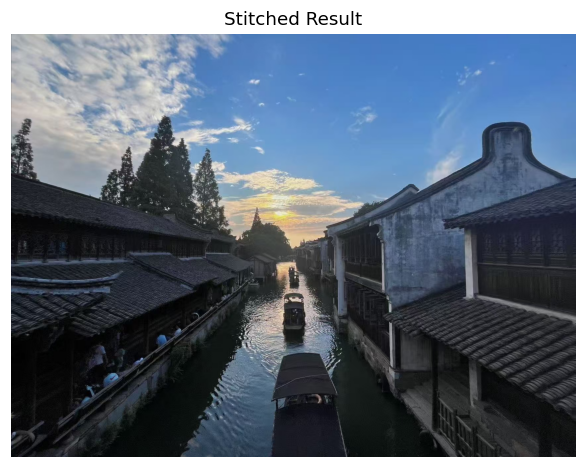

In [6]:
t0 = time.time()

h_a, w_a = img_a.shape[:2]
h_b, w_b = img_b.shape[:2]

pts = np.float32([[0, 0], [0, h_b], [w_b, h_b], [w_b, 0]]).reshape(-1, 1, 2)
dst_corners = cv2.perspectiveTransform(pts, H)
a_corners = np.float32([[0, 0], [w_a, 0], [w_a, h_a], [0, h_a]]).reshape(-1, 1, 2)

all_corners = np.concatenate([dst_corners, a_corners], axis=0)
x_min, y_min = np.int32(all_corners.min(axis=0).ravel() - 0.5)
x_max, y_max = np.int32(all_corners.max(axis=0).ravel() + 0.5)

T = np.array([[1, 0, -x_min], [0, 1, -y_min], [0, 0, 1]], dtype=np.float32)

stitched = cv2.warpPerspective(img_b, T @ H, (x_max - x_min, y_max - y_min))
stitched[-y_min:h_a - y_min, -x_min:w_a - x_min] = img_a

print('画布尺寸', stitched.shape)
print('耗时', round(time.time() - t0, 2), '秒')

cv2.imwrite(os.path.join(OUT_RES, 'stitched_result.jpg'), stitched)

plt.figure(figsize=(9, 5))
plt.imshow(cv2.cvtColor(stitched, cv2.COLOR_BGR2RGB))
plt.title('Stitched Result')
plt.axis('off')
plt.savefig(os.path.join(OUT_RES, 'stitch_view.jpg'), dpi=200, bbox_inches='tight')
plt.show()


## 2.7 拼接质量检查

拼接好不好，主要看两点：一是重叠区里 a 图和变换后的 b 图内容对不对得上，灰度差越小说明 H 估得越准；二是画布四角有没有留下大片黑边。这里统计重叠区的灰度差分布，顺便把有效区域外接框裁出来。


黑边像素占比 0.0005
重叠区像素数 668160
重叠区平均灰度差 2.01
重叠区灰度差95%分位 7.0
重叠区灰度差最大值 51
裁剪后尺寸 (1280, 1707, 3)


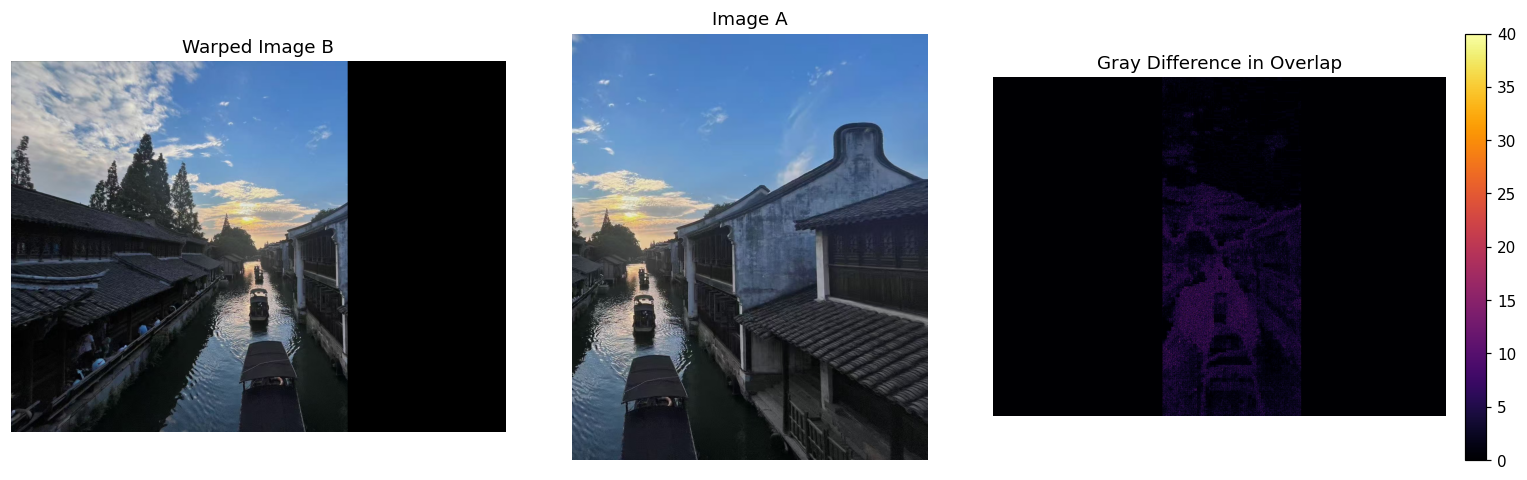

In [7]:
mask_b = cv2.warpPerspective(np.ones((h_b, w_b), np.uint8), T @ H,
                              (x_max - x_min, y_max - y_min))
mask_a = np.zeros_like(mask_b)
mask_a[-y_min:h_a - y_min, -x_min:w_a - x_min] = 1
valid = cv2.bitwise_or(mask_b, mask_a)

gray_stitch = cv2.cvtColor(stitched, cv2.COLOR_BGR2GRAY)
black_ratio = float((gray_stitch == 0).sum()) / gray_stitch.size
print('黑边像素占比', round(black_ratio, 4))

warped_b = cv2.warpPerspective(img_b, T @ H, (x_max - x_min, y_max - y_min))
gray_wb = cv2.cvtColor(warped_b, cv2.COLOR_BGR2GRAY)
gray_a_canvas = np.zeros_like(gray_wb)
gray_a_canvas[-y_min:h_a - y_min, -x_min:w_a - x_min] = gray_a

overlap = cv2.bitwise_and(mask_a, mask_b) > 0
diff = cv2.absdiff(gray_a_canvas, gray_wb)
d = diff[overlap]

print('重叠区像素数', int(overlap.sum()))
print('重叠区平均灰度差', round(float(d.mean()), 2))
print('重叠区灰度差95%分位', round(float(np.percentile(d, 95)), 2))
print('重叠区灰度差最大值', int(d.max()))

ys, xs = np.where(valid > 0)
cropped = stitched[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
print('裁剪后尺寸', cropped.shape)
cv2.imwrite(os.path.join(OUT_RES, 'stitched_cropped.jpg'), cropped)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
axes[0].imshow(cv2.cvtColor(warped_b, cv2.COLOR_BGR2RGB))
axes[0].set_title('Warped Image B')
axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(img_a, cv2.COLOR_BGR2RGB))
axes[1].set_title('Image A')
axes[1].axis('off')
im = axes[2].imshow(np.where(overlap, diff, 0), cmap='inferno', vmin=0, vmax=40)
axes[2].set_title('Gray Difference in Overlap')
axes[2].axis('off')
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(os.path.join(OUT_RES, 'overlap_diff.jpg'), dpi=200, bbox_inches='tight')
plt.show()


## 小结

- **SIFT**：关键点带尺度和方向，描述符 128 维，对旋转、缩放、亮度变化都比较稳。
- **Lowe 比率检验**：最近邻距离小于次近邻的 0.7 倍才保留，能去掉大部分区分度不高的匹配。
- **RANSAC**：从匹配点里随机抽 4 对估 H，反复取内点最多的一组，把残余错配剔掉。
- **拼接**：先把所有角点合起来求外接框，再用平移矩阵把负坐标推正，最后把 a 图贴回画布。
